In [1]:
!pip install -q transformers albumentations timm evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00


In [2]:
import os
import random
import math
import numpy as np
from glob import glob
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import SegformerForSemanticSegmentation, SegformerFeatureExtractor
import albumentations as A
from tqdm import tqdm


2025-12-18 09:52:49.210297: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766051569.402341     106 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766051569.459506     106 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1766051569.923213     106 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766051569.923244     106 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1766051569.923247     106 computation_placer.cc:177] computation placer alr

In [ ]:
DATA_ROOT = "/kaggle/input/whu-building-dataset/WHU"
IMAGES_DIR = f"{DATA_ROOT}/train/Image"
MASKS_DIR  = f"{DATA_ROOT}/train/Mask"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE = 512
BATCH_SIZE = 32 
EPOCHS = 50
LR = 6e-5
NUM_CLASSES = 2
TAU = 0.6
KD_WEIGHT = 0.5
TEMPERATURE = 4.0
NUM_WORKERS = 4

STUDENT_SAVE_PATH = "student_best_earlystop.pth"
TEACHER_CKPT_PATH = (
    "/kaggle/input/segformer-mit-b1-whu-building/"
    "pytorch/default/1/"
    "best_segformer_mit_b1_epoch50_iou0.8283.pt"
)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)


In [4]:
class WHUDataset(Dataset):
    def __init__(self, img_paths, mask_paths, feature_extractor, augment=None):
        self.imgs = img_paths
        self.masks = mask_paths
        self.fe = feature_extractor
        self.augment = augment

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.imgs[idx]).convert("RGB"))
        mask = np.array(Image.open(self.masks[idx]).convert("L"))
        mask = (mask > 127).astype(np.uint8)

        if self.augment:
            aug = self.augment(image=img, mask=mask)
            img, mask = aug["image"], aug["mask"]

        enc = self.fe(images=img, return_tensors="pt")
        pixel_values = enc.pixel_values.squeeze(0)
        mask = torch.from_numpy(mask).long()

        return pixel_values, mask


In [5]:
imgs = sorted(glob(IMAGES_DIR + "/*"))
masks = sorted(glob(MASKS_DIR + "/*"))

pairs = list(zip(imgs, masks))
random.shuffle(pairs)

train_pairs = pairs[:2000]
val_pairs   = pairs[2000:2400]

fe = SegformerFeatureExtractor(do_resize=False, do_normalize=True)

train_tf = A.Compose([
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(),
    A.VerticalFlip(),
])

val_tf = A.Compose([
    A.CenterCrop(IMG_SIZE, IMG_SIZE)
])

train_ds = WHUDataset(
    [p[0] for p in train_pairs],
    [p[1] for p in train_pairs],
    fe,
    train_tf
)

val_ds = WHUDataset(
    [p[0] for p in val_pairs],
    [p[1] for p in val_pairs],
    fe,
    val_tf
)

train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


/usr/local/lib/python3.12/dist-packages/transformers/models/segformer/feature_extraction_segformer.py:30: FutureWarning: The class SegformerFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use SegformerImageProcessor instead.
  warnings.warn(


In [ ]:
# Student (small)
student = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=2,
    id2label={0: "bg", 1: "building"},
    label2id={"bg": 0, "building": 1},
    ignore_mismatched_sizes=True
).to(DEVICE)

# Teacher (large)
teacher = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b1",
    num_labels=2,
    id2label={0: "bg", 1: "building"},
    label2id={"bg": 0, "building": 1},
    ignore_mismatched_sizes=True
).to(DEVICE)

ckpt = torch.load(
    TEACHER_CKPT_PATH,
    map_location=DEVICE,
    weights_only=False 
)

teacher.load_state_dict(ckpt["model_state_dict"], strict=True)

teacher.eval()
for p in teacher.parameters():
    p.requires_grad = False

print("✅ Teacher loaded successfully")


x = torch.randn(1, 3, 512, 512).to(DEVICE)
with torch.no_grad():
    out = teacher(pixel_values=x).logits

print("Teacher output shape:", out.shape)


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/15.0M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b0-finetuned-ade-512-512 and are newly initialized because the shapes did not match:
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([2]) in the model instantiated
- decode_head.classifier.weight: found shape torch.Size([150, 256, 1, 1]) in the checkpoint and torch.Size([2, 256, 1, 1]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/54.7M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/54.7M [00:00<?, ?B/s]

✅ Teacher loaded successfully
Teacher output shape: torch.Size([1, 2, 128, 128])


In [9]:
criterion_sup = nn.CrossEntropyLoss()

def kd_loss(student_logits, teacher_logits, T=4.0, mask=None):
    s = F.log_softmax(student_logits / T, dim=1)
    t = F.softmax(teacher_logits / T, dim=1)
    kl = F.kl_div(s, t, reduction="none") * (T * T)

    if mask is not None:
        kl = kl * mask

    return kl.mean()


In [10]:
optimizer = torch.optim.AdamW(student.parameters(), lr=LR, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler()

/tmp/ipykernel_106/1067574641.py:2: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [11]:
def evaluate_iou(model, loader):
    model.eval()
    ious = []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(pixel_values=x).logits
            logits = F.interpolate(logits, y.shape[-2:], mode="bilinear", align_corners=False)

            preds = torch.argmax(logits, dim=1)
            inter = ((preds==1) & (y==1)).sum()
            union = ((preds==1) | (y==1)).sum()

            if union > 0:
                ious.append((inter/union).item())

    return float(np.mean(ious))


In [12]:
best_iou = 0.0

for epoch in range(1, EPOCHS+1):
    student.train()
    total_loss = 0

    for x, y in tqdm(train_loader, desc=f"Epoch {epoch}"):
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            s_logits = student(pixel_values=x).logits
            s_logits = F.interpolate(s_logits, y.shape[-2:], mode="bilinear", align_corners=False)
            loss_sup = criterion_sup(s_logits, y)

            with torch.no_grad():
                t_logits = teacher(pixel_values=x).logits
                t_logits = F.interpolate(t_logits, y.shape[-2:], mode="bilinear", align_corners=False)
                t_probs = F.softmax(t_logits, dim=1)
                conf,_ = torch.max(t_probs, dim=1, keepdim=True)
                mask = (conf > TAU).float()

            loss_kd = kd_loss(s_logits, t_logits, TEMPERATURE, mask)
            loss = loss_sup + KD_WEIGHT * loss_kd

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    val_iou = evaluate_iou(student, val_loader)
    print(f"Epoch {epoch} | Loss {total_loss:.4f} | Val IoU {val_iou:.4f}")

    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(student.state_dict(), STUDENT_SAVE_PATH)
        print("✅ Saved best student")


Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]/tmp/ipykernel_106/545632002.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1: 100%|██████████| 63/63 [00:25<00:00,  2.50it/s]


Epoch 1 | Loss 86.9012 | Val IoU 0.5965
✅ Saved best student


Epoch 2: 100%|██████████| 63/63 [00:09<00:00,  6.49it/s]


Epoch 2 | Loss 56.9553 | Val IoU 0.6983
✅ Saved best student


Epoch 3: 100%|██████████| 63/63 [00:09<00:00,  6.38it/s]


Epoch 3 | Loss 42.9573 | Val IoU 0.7198
✅ Saved best student


... (90 outputs left out)

Epoch 49: 100%|██████████| 63/63 [00:10<00:00,  6.27it/s]


Epoch 49 | Loss 4.7724 | Val IoU 0.8509


Epoch 50: 100%|██████████| 63/63 [00:10<00:00,  6.29it/s]


Epoch 50 | Loss 4.7825 | Val IoU 0.8504


In [ ]:
FINAL_STUDENT_PATH = "student_final.pth"
torch.save(student.state_dict(), FINAL_STUDENT_PATH)

def model_size_mb(path):
    return round(os.path.getsize(path) / 1024 / 1024, 2)

print("Student model size (MB):", model_size_mb(FINAL_STUDENT_PATH))
print("Teacher checkpoint size (MB):", model_size_mb(TEACHER_CKPT_PATH))


Student model size (MB): 14.25
Teacher checkpoint size (MB): 156.8


In [ ]:
def evaluate_student_metrics(model, loader):
    model.eval()

    TP = FP = FN = TN = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(pixel_values=x).logits
            logits = F.interpolate(logits, y.shape[-2:], mode="bilinear", align_corners=False)

            preds = torch.argmax(logits, dim=1)

            TP += ((preds == 1) & (y == 1)).sum().item()
            FP += ((preds == 1) & (y == 0)).sum().item()
            FN += ((preds == 0) & (y == 1)).sum().item()
            TN += ((preds == 0) & (y == 0)).sum().item()

    eps = 1e-6
    IoU = TP / (TP + FP + FN + eps)
    Dice = (2 * TP) / (2 * TP + FP + FN + eps)
    Precision = TP / (TP + FP + eps)
    Recall = TP / (TP + FN + eps)
    F1 = 2 * Precision * Recall / (Precision + Recall + eps)
    Accuracy = (TP + TN) / (TP + TN + FP + FN + eps)

    metrics = {
        "IoU": IoU,
        "Dice": Dice,
        "Precision": Precision,
        "Recall": Recall,
        "F1": F1,
        "Accuracy": Accuracy
    }

    print("===================================")
    print("     FINAL STUDENT METRICS")
    print("===================================")
    for k, v in metrics.items():
        print(f"{k:<10}: {v:.4f}")
    print("===================================")

    return metrics


student_metrics = evaluate_student_metrics(student, val_loader)


     FINAL STUDENT METRICS
IoU       : 0.8517
Dice      : 0.9199
Precision : 0.9276
Recall    : 0.9124
F1        : 0.9199
Accuracy  : 0.9734


In [ ]:
import pandas as pd

metrics_df = pd.DataFrame([student_metrics])
metrics_df.index = ["Student_SegFormer_B0"]

metrics_df.to_csv("student_metrics.csv")
print("✅ Saved student_metrics.csv")


✅ Saved student_metrics.csv


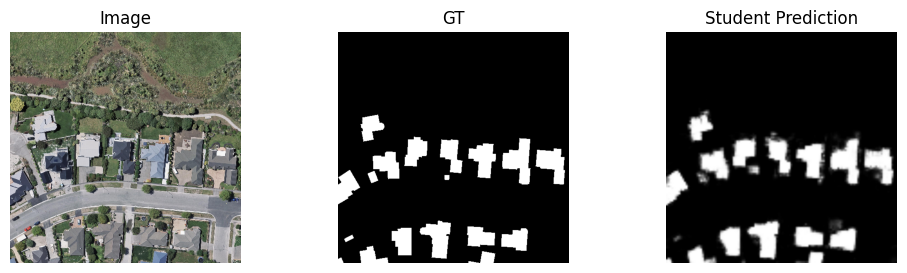

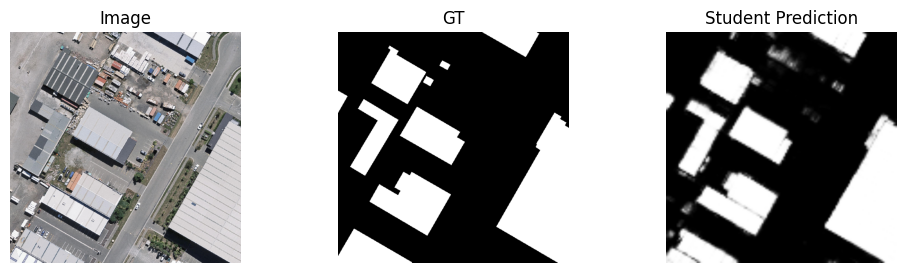

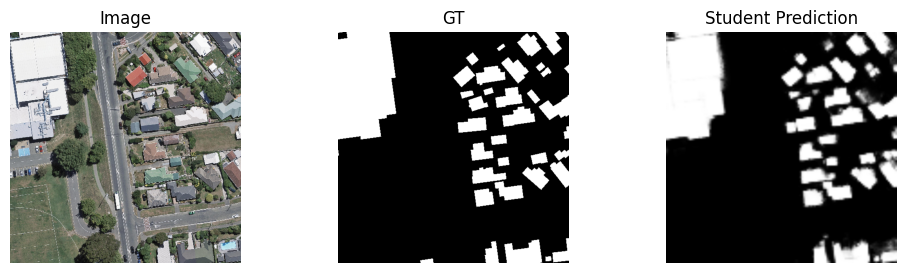

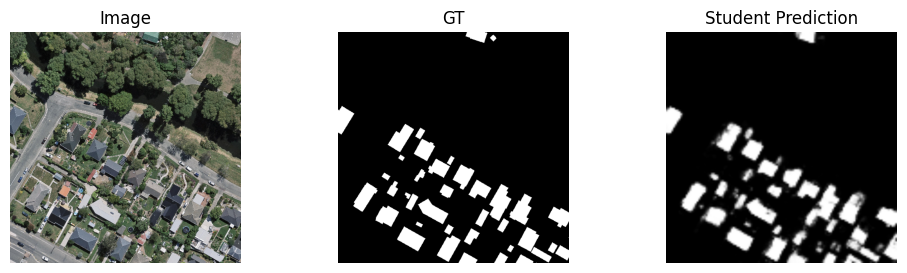

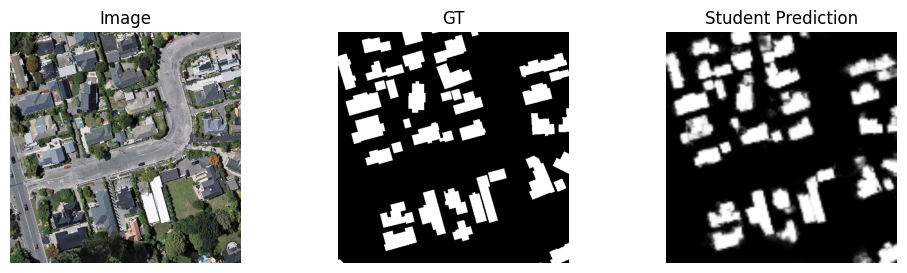

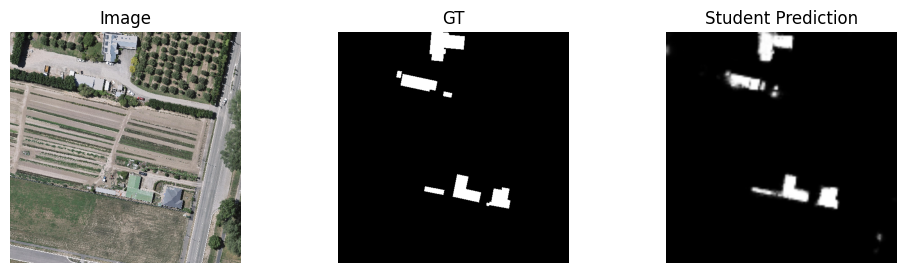

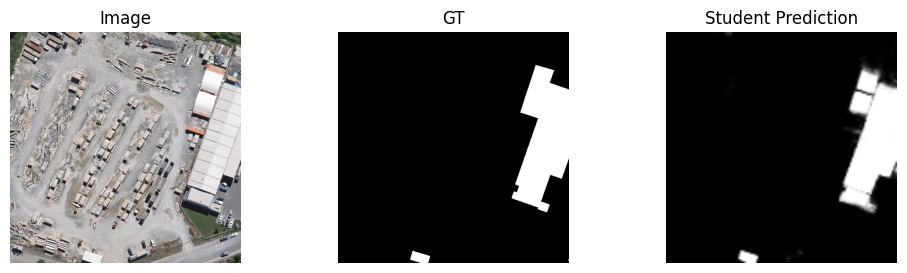

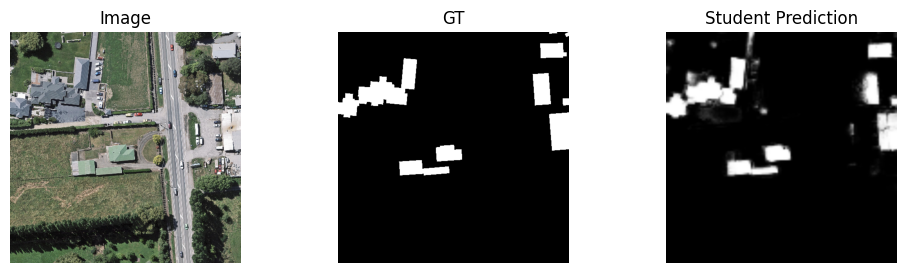

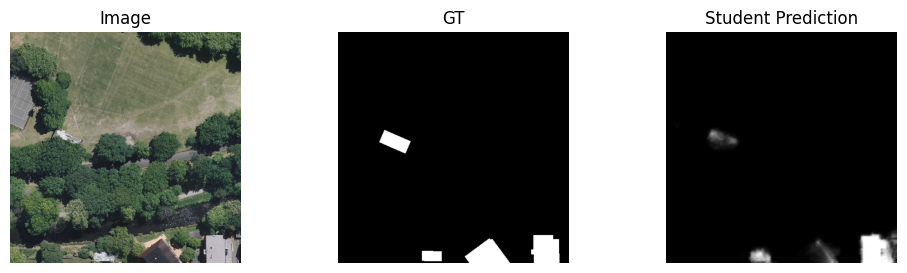

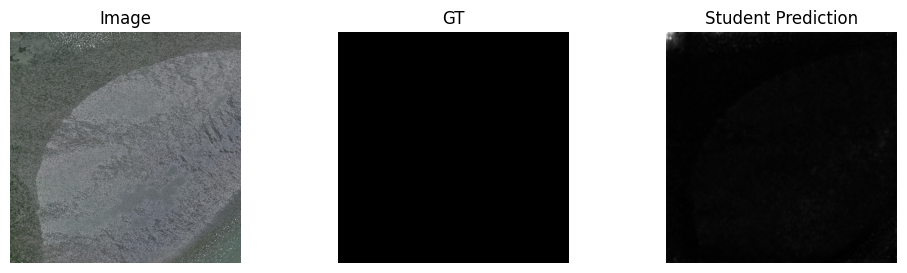

✅ Saved qualitative predictions


In [ ]:
import matplotlib.pyplot as plt
import cv2

os.makedirs("qualitative_results", exist_ok=True)

def show_and_save_predictions(num=5):
    idxs = random.sample(range(len(val_pairs)), num)

    for i in idxs:
        img_path, mask_path = val_pairs[i]

        img = np.array(Image.open(img_path).convert("RGB"))
        gt  = np.array(Image.open(mask_path).convert("L"))
        gt  = (gt > 127).astype(np.uint8)

        enc = fe(images=img, return_tensors="pt")
        x = enc.pixel_values.to(DEVICE)

        with torch.no_grad():
            logits = student(pixel_values=x).logits
            probs = torch.softmax(logits, dim=1)[0,1].cpu().numpy()

        probs = cv2.resize(probs, (IMG_SIZE, IMG_SIZE))

        plt.figure(figsize=(12,3))
        plt.subplot(1,3,1); plt.imshow(img); plt.title("Image"); plt.axis("off")
        plt.subplot(1,3,2); plt.imshow(gt, cmap="gray"); plt.title("GT"); plt.axis("off")
        plt.subplot(1,3,3); plt.imshow(probs, cmap="gray"); plt.title("Student Prediction"); plt.axis("off")

        save_path = f"qualitative_results/sample_{i}.png"
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

    print("✅ Saved qualitative predictions")

show_and_save_predictions(10)


In [22]:
summary = f"""
Student SegFormer-B0 Results (KD Trained)

IoU        : {student_metrics['IoU']:.4f}
Dice       : {student_metrics['Dice']:.4f}
Precision  : {student_metrics['Precision']:.4f}
Recall     : {student_metrics['Recall']:.4f}
F1-score   : {student_metrics['F1']:.4f}
Accuracy   : {student_metrics['Accuracy']:.4f}

Teacher Model Size (MB): {model_size_mb(TEACHER_CKPT_PATH)}
Student Model Size (MB): {model_size_mb(FINAL_STUDENT_PATH)}
"""

with open("final_report_summary.txt", "w") as f:
    f.write(summary)

print("✅ Saved final_report_summary.txt")


✅ Saved final_report_summary.txt
